In [11]:
# -------------------------------------------
# 
# plot GCAM and SCEPTER derived CDR estimates
# 
# -------------------------------------------
import os

import cmocean as cmo
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr

In [114]:
# --- read in data
#  ----------------------------------------------------------------
# [ RUN NAMES ]
# exe_central1p5 ; exe_central2p0 ; exe_limBio1p5 ; exe_lowCCS1p5 ; 
# exe_lowCDR1p5 ; exe_noBiochar1p5 ; exe_noWeathering1p5 ; 
# exe_ref1p5 ; exe_techBehaviorChange1p5 ; exe_techBehaviorChange2p0 ;
# ----------------------------------------------------------------
#
# # [---gcam_opr3 groups---]
# EXP_GROUPS = [
#     "psdfull_lowcec", "psdfull_hicec",
#     "psdfull_smooth", "psdfull_hicec_smooth",
#     "psdfull_loWx", "psdfull_25diam",
# ]
#
#
exp_group_prefix = "gcam_opr2_"
# 
EXP_GROUPS = [
    "psdfull_nocec", "psdfull_lowcec",
    "psdfull_hicec", 
    "max5tha",  "psdfull_10xrough",
    "psdfull_midcec_10xrough",
    "nopsd", "psdfull_5xrough", #"nopsd_10xrough",
    "psdfull_midcec_5xrough",
    "psdfull_midcec_5xrough_max5tha"
]
# 
# ************************************************
# --- SCEPTER outputs
EXP_SET = "exe_noWeathering1p5"
idx = "001"
fn_cdr = "ds_cdr.zarr"   # time-integrated data
fn_cdr_trans = "ds_cdr_transient.zarr"  # time-transient data
# 
ds_dict = {}
ds_trans_dict = {}
for EXP_GROUP in EXP_GROUPS:
    if EXP_GROUP in ["max10tha", "max5tha", "2xRock", "psdfull_midcec_5xrough_max5tha"]: 
        if EXP_GROUP in ["psdfull_midcec_5xrough_max5tha"]:
            this_EXP_GROUP = "max5tha"
        else:
            this_EXP_GROUP = EXP_GROUP
        thisgroup = f"{exp_group_prefix}psdfull"
        EXP_SET_tmp = f"{EXP_SET}_{this_EXP_GROUP}"
    else:
        thisgroup = exp_group_prefix + EXP_GROUP
        EXP_SET_tmp = EXP_SET
    dir_postproc = f's3://carbonplan-carbon-removal/ew-workflows-data/scepter/postprocessed/{thisgroup}/{EXP_SET_tmp}_{idx}'
    # [ read in ]
    ds_dict[EXP_GROUP] = xr.open_zarr(os.path.join(dir_postproc, fn_cdr))
    ds_trans_dict[EXP_GROUP] = xr.open_zarr(os.path.join(dir_postproc, fn_cdr_trans))

# ************************************************
# --- GCAM outputs
run_format = 'one-cell-per-region'
deg_resolution = 1
gcam_fn = f'annual_rockflx_densest-ag-region_{deg_resolution}deg.pkl'
gcam_dir = f's3://carbonplan-carbon-removal/ew-workflows-data/gcam/apprate_calculated/{run_format}/{EXP_SET}'
# [ read in ]
df = pd.read_pickle(os.path.join(gcam_dir, gcam_fn))

# ************************************************
# --- derived ag map 
# ( only need one ag map )
run_format = 'one-cell-per-region'
deg_resolution = 1
gcam_dir = f's3://carbonplan-carbon-removal/ew-workflows-data/gcam/apprate_calculated/{run_format}/{EXP_SET}'
gcam_fn = f'cropland+gcamRegions_time_{deg_resolution}deg.zarr'
# [ read in ]
dsag = xr.open_zarr(os.path.join(gcam_dir, gcam_fn))

In [115]:
# --- compute global GCAM CDR 
df_global = (
    df.groupby("time", as_index=False)["gcam_gross_cdr_mtCO2"]
    .sum()
    .assign(region="globe")
)
# --- assume fixed emissions per ton of rock
# since gcam cdr is directly proportional to rock application, we
# assume fixed emissions as a percentage of gcam cdr 
df_global['emiss_10percent'] = df_global['gcam_gross_cdr_mtCO2'] * 0.1

## Calculate global CDR from SCEPTER outputs
Each pixel (or site) in SCEPTER outputs CDR in tonnes/ha. If we have one pixel per region, then we need to muliply by the cropland area in the region to get the total tonnes. 

Note that the cropland area units are m2. 1 ha = 1 m2/1000.

In [116]:
# [ list vars to scale by area ] -----------------------
vars_to_scale_by_area = [
    'cdr_adv', 'cdr_adv_plus_newSIC', 'cdr_dif', 'cdr_dif_component',
    'cdr_resp_component', 'cdr_resp_component_noAE', 'cdr_SIConly', 
    'co2pot_adv_tonHa_camg', 'co2pot_adv_tonHa_totcat', 'co2pot_tot_tonHa_camg',
    'co2pot_tot_tonHa_totcat', 'DICpot_adv_camg', 'DICpot_adv_totcat',
    'int_dust_ton_ha_yr', 
]
vars_to_scale_by_area_trans = [
    'cdr_adv', 'cdr_adv_plus_newSIC', 'cdr_dif', 'cdr_dif_component',
    'cdr_resp_component', 'cdr_resp_component_noAE', 'cdr_SIConly', 
    'co2pot_adv_tonHaYr_camg', 'co2pot_adv_tonHaYr_totcat', 'co2pot_tot_tonHaYr_camg',
    'co2pot_tot_tonHaYr_totcat', 'DICpot_adv_camg', 'DICpot_adv_totcat',
    'int_dust_ton_ha_yr', 
]
# ------------------------------------------------------
# 
for EXP_GROUP in EXP_GROUPS:
    # 
    # --- calculate global annual CDR 
    # [ get cropland area for each region ]
    dfreg_t0 = df.groupby("region", as_index=False).first().copy() # df of regional data (1 row / region, no time)
    dfreg_t0['cropland_area_by_region'] = dsag["cropland_area_by_region"].sel(
        y=xr.DataArray(dfreg_t0["lat"].values, dims="points"),
        x=xr.DataArray(dfreg_t0["lon"].values, dims="points"),
    )
    # convert area from m2 to hectares
    dfreg_t0['cropland_area_by_region_hectares'] = dfreg_t0['cropland_area_by_region'] / 1e4
    # align df regions to ds sites for later calculation
    area_series = (
        dfreg_t0.set_index("region_nospaces")["cropland_area_by_region_hectares"]
    )
    area_series.index.name = "site"
    area_da = xr.DataArray(
        area_series,
        dims="site",
        coords={"site": area_series.index}
    )
    # 
    # =========================================================================
    for var in vars_to_scale_by_area:
        # [ calculate vars in tonnes / yr for each region (multiply by hectares) ]
        ds_dict[EXP_GROUP][f'{var}_xCropArea'] = ds_dict[EXP_GROUP][var] * area_da
        ds_dict[EXP_GROUP][f'{var}_xCropArea'].attrs['note'] = f"Var {var} multiplied by regional hectares of cropland"
    for var_trans in vars_to_scale_by_area_trans:
        # [ repeat for transient data ]
        ds_trans_dict[EXP_GROUP][f'{var_trans}_xCropArea'] = ds_trans_dict[EXP_GROUP][var_trans] * area_da
        ds_trans_dict[EXP_GROUP][f'{var_trans}_xCropArea'].attrs['note'] = f"Var {var_trans} multiplied by regional hectares of cropland"

In [117]:
# --- apply rock feedstock RCO2 correction
cdr_vars = [
    'cdr_adv', 'cdr_adv_plus_newSIC', 'cdr_dif', 'cdr_dif_component',
    'cdr_resp_component', 'cdr_resp_component_noAE', 'cdr_SIConly', 
    'co2pot_adv_tonHa_camg', 'co2pot_adv_tonHa_totcat', 'co2pot_tot_tonHa_camg',
    'co2pot_tot_tonHa_totcat', 'DICpot_adv_camg', 'DICpot_adv_totcat',
]
cdr_vars_trans = [
    'cdr_adv', 'cdr_adv_plus_newSIC', 'cdr_dif', 'cdr_dif_component',
    'cdr_resp_component', 'cdr_resp_component_noAE', 'cdr_SIConly', 
    'co2pot_adv_tonHaYr_camg', 'co2pot_adv_tonHaYr_totcat', 'co2pot_tot_tonHaYr_camg',
    'co2pot_tot_tonHaYr_totcat', 'DICpot_adv_camg', 'DICpot_adv_totcat',
]
# =========================================================================
rco2_gcam = 0.3
rco2_gbas = 0.41
corr_factor = rco2_gcam / rco2_gbas
for EXP_GROUP in EXP_GROUPS:
    for var in vars_to_scale_by_area:
        # [ calculate vars in tonnes / yr for each region (multiply by hectares) ]
        ds_dict[EXP_GROUP][f'{var}_xCropArea_corr'] = ds_dict[EXP_GROUP][f'{var}_xCropArea'] * corr_factor
        ds_dict[EXP_GROUP][f'{var}_xCropArea_corr'].attrs['note'] = f"Var {var} multiplied by regional hectares of cropland and corrected for different feedstock RCO2 compared to gcam"
    for var_trans in vars_to_scale_by_area_trans:
        # [ repeat for transient data ]
        ds_trans_dict[EXP_GROUP][f'{var_trans}_xCropArea_corr'] = ds_trans_dict[EXP_GROUP][f'{var_trans}_xCropArea'] * corr_factor
        ds_trans_dict[EXP_GROUP][f'{var_trans}_xCropArea_corr'].attrs['note'] = f"Var {var} multiplied by regional hectares of cropland and corrected for different feedstock RCO2 compared to gcam"

## Plot scepter vs gcam cases

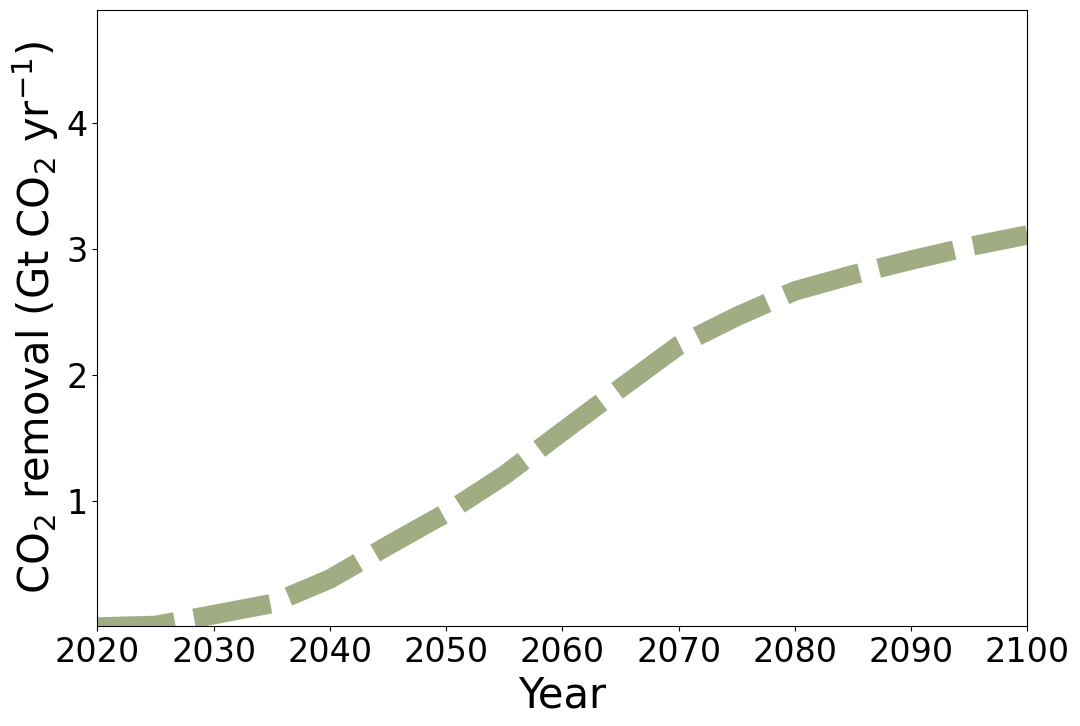

In [118]:
spotlight_cases = ["psdfull_nocec"]
# ---------------------------------
# [ aesthetics ]
# colors
line_cmap_gcam = cmo.cm.rain_r # Choose a cmocean colormap
cmap_gcam_start = 0.1
cmap_gcam_end = 0.7
line_cmap_scep = cmo.cm.matter
cmap_scep_start = 0.1
cmap_scep_end = 0.9
allcases_col = 'black'
allcases_alph = 0.8
# lines
apply_smooth = True  # [] whether to smooth SCEPTER's lines 
ls_case = 14
ls_bg = 8
lstyle_gcam = (0, (4,1))
# legend
legend_on = False
# fontsizes 
fs_ticks = 24
fs_lab = 30
fs_legend = 20
# ---------------------------------
# [ EXP GROUPS TO PLOT ]
EXP_GROUPS_toplot = [
    # "psdfull_nocec", # "psdfull_lowcec",
    # "psdfull_hicec", # "psdfull_5xrough",
    # "psdfull_midcec_5xrough",
    # "max5tha",  "psdfull_10xrough",
    # "psdfull_midcec_10xrough",
    # "nopsd",  #"nopsd_10xrough",
    # "psdfull_midcec_5xrough_max5tha"
]
EXP_GROUPS_toplot_MAX = [ # [ ALL cases we want to eventually plot to scale colorbar ]
    "psdfull_nocec", # "psdfull_lowcec",
    "psdfull_hicec", "psdfull_5xrough",
    "psdfull_midcec_5xrough",
]
EXP_GROUP_labels = {
    "psdfull_nocec": "high CDR", 
    "psdfull_lowcec": "small sponge",
    "psdfull_hicec": "sponge",
    "psdfull_5xrough": "less rough",
    "psdfull_midcec_5xrough": "sponge + less rough",
    "psdfull_loWx": "Tx", 
    "psdfull_25diam": "ultfine"
}
scale_factors = {
    "exe_central1p5": {
        "psdfull_nocec": 1.3, "psdfull_lowcec": 1, "psdfull_hicec": 1, "psdfull_5xrough": 1,
        "psdfull_midcec_5xrough": 1, "psdfull_loWx": 1, "psdfull_25diam":1,
    },
    "exe_noWeathering1p5": {
        "psdfull_nocec": 1.3, "psdfull_lowcec": 1, "psdfull_hicec": 1, "psdfull_5xrough": 1,
        "psdfull_midcec_5xrough": 1, "psdfull_loWx": 1, "psdfull_25diam":1,
    }
}
# ---------------------------------

casesonly = True
cases_to_plot = ['exe_central1p5', 'exe_noWeathering1p5']
cases_to_omit = ['exe_ref1p5'] # ref is no policy, and Fuhrman omits it from their figures
casenames = {'exe_central1p5': 'Main', 
             'exe_lowCDR1p5': 'Lower CDR deployment', 
             'exe_noWeathering1p5': 'High-cost ERW', 
             'exe_techBehaviorChange1p5': 'Ambitious behavior change'}
# GCAM --- set colors
n_lines = len(cases_to_plot)
colors = [line_cmap_gcam(i) for i in np.linspace(cmap_gcam_start, cmap_gcam_end, n_lines)]  # spaced colors
order = [0,1]
colors_sorted = [colors[i] for i in order]
# SCEPTER --- set colors
n_lines = len(EXP_GROUPS_toplot_MAX)
colors_scep = [line_cmap_scep(i) for i in np.linspace(cmap_scep_start, cmap_scep_end, n_lines)]  # spaced colors


# pick color for the gcam line 
col_idx = cases_to_plot.index(EXP_SET)

# [ PLOT ] --------------------------------------------------
plt.figure(figsize=(12,8))
# --- gcam line
plt.plot(df_global['time'], df_global['gcam_gross_cdr_mtCO2']/1e3, c=colors_sorted[col_idx], linewidth=ls_case, linestyle=lstyle_gcam, label=f'GCAM: {casenames[EXP_SET]}')
# --- scepter lines 
col_scep_idx = 0
for EXP_GROUP in EXP_GROUPS_toplot: # scepter data
    tds_trans = ds_trans_dict[EXP_GROUP]
    xp = tds_trans.time+2020
    yp = tds_trans['cdr_adv_xCropArea_corr'].sum('site')/1e9 * scale_factors[EXP_SET][EXP_GROUP]
    if apply_smooth:
        yp = yp.rolling(time=3, center=True, min_periods=1).mean()
    if EXP_GROUP in spotlight_cases: # give it a thicker line
        plt.plot(xp, yp, label=f'RTM: {EXP_GROUP_labels[EXP_GROUP]}', linewidth=ls_case, c=colors_scep[col_scep_idx])
    else:
        # [ with label ]
        plt.plot(xp, yp, label=f'RTM: {EXP_GROUP_labels[EXP_GROUP]}', linewidth=ls_bg, c=colors_scep[col_scep_idx])
        # [ without label ]
        # plt.plot(xp, yp, linewidth=ls_bg, c=colors_scep[col_scep_idx])
    col_scep_idx+=1
if legend_on: 
    handles, labels = plt.gca().get_legend_handles_labels()
    # reorder handles and labels
    # order_leg = len(EXP_GROUPS_toplot)
    # handles = [handles[i] for i in order_leg]
    # labels  = [labels[i] for i in order_leg]
    # draw the legend in the new order
    plt.legend(handles, labels, fontsize=fs_legend)
plt.tick_params(labelsize=fs_ticks)
plt.ylabel(r"CO$_2$ removal (Gt CO$_2$ yr$^{-1}$)", fontsize=fs_lab)
plt.xlabel("Year", fontsize=fs_lab)
plt.xlim(2020, 2100)
plt.ylim(0.01,4.9)
# plt.yscale('log')
plt.show()
plt.close();

### SCEPTER fraction GCAM integrated CDR

In [79]:
# --- compute time-integrated CDR in Gt
gcam_int = []
scepter_int = []
ratio_int = []
exps = []
bar_color = []
bar_col_idx = 0
for EXP_GROUP in EXP_GROUPS_toplot:
    exps.append(EXP_GROUP)
    tds = ds_dict[EXP_GROUP]
    # get integrated cdr timeseries
    gcam_tmp = df_global['gcam_gross_cdr_mtCO2'].cumsum() / 1e3   # [Gt]
    scepter_tmp = ds_dict[EXP_GROUP]['cdr_adv_xCropArea_corr'].sum('site')/1e9 * scale_factors[EXP_SET][EXP_GROUP] # [Gt]
    # get final values
    gcam_int.append(gcam_tmp.values[-1])
    scepter_int.append(scepter_tmp.values[-1])
    ratio_int.append(scepter_tmp.values[-1] / gcam_tmp.values[-1])
    # assign colors 
    bar_color.append(colors_scep[bar_col_idx])
    bar_col_idx += 1

# --- sort by height
idx = np.argsort(ratio_int)[::-1]
exps_sorted = np.array(exps)[idx]
ratio_sorted = np.array(ratio_int)[idx]
bar_color_sorted = np.array(bar_color)[idx]


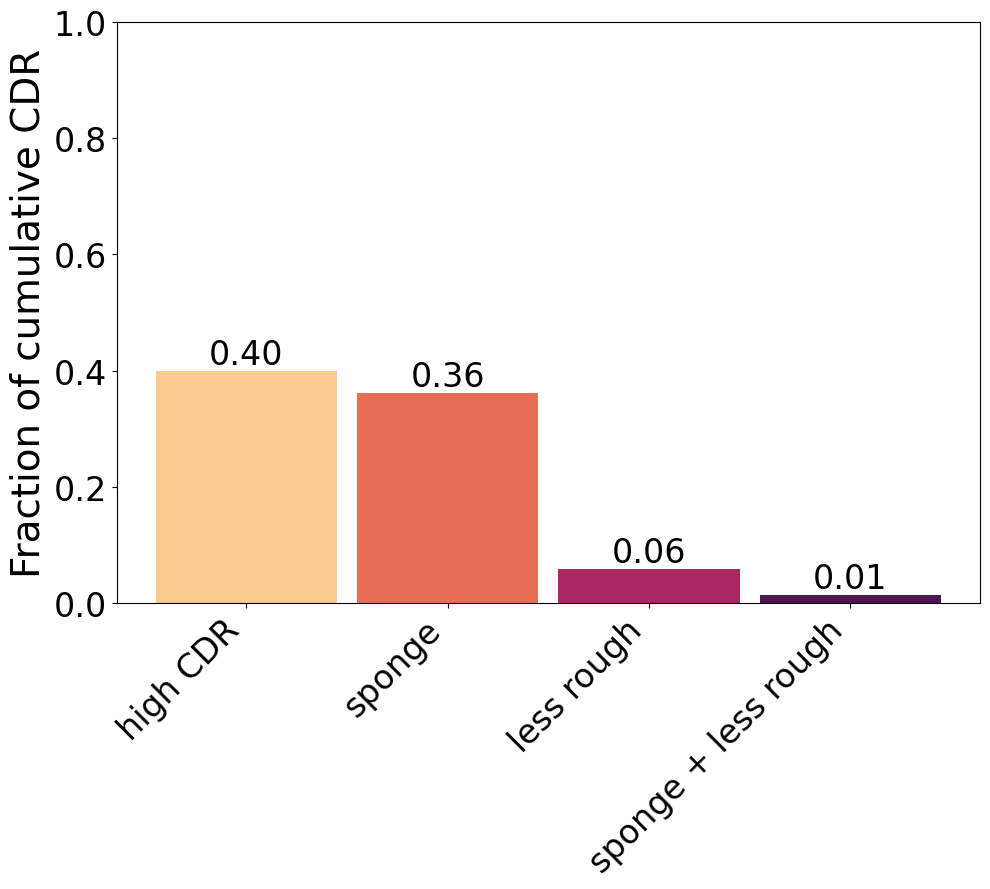

In [80]:
# ---------------------------------
# [ aesthetics ]
# colors
line_cmap_scep = cmo.cm.matter
cmap_scep_start = 0.1
cmap_scep_end = 0.9
allcases_col = 'black'
allcases_alph = 0.8
# fontsizes 
fs_ticks = 24
fs_lab = 28
fs_legend = 18
# ---------------------------------
# get plot indices
plot_indices = np.where(np.isin(exps_sorted, EXP_GROUPS_toplot))[0]
# get the new x-axis labels
xlab_sorted = np.array([EXP_GROUP_labels[exp] for exp in exps_sorted])
x = np.arange(len(xlab_sorted[plot_indices]))
# ---------------------------------
#
#
# --- PLOT
plen = 10 * (len(EXP_GROUPS_toplot)/len(EXP_GROUPS_toplot_MAX)) 
fig, ax = plt.subplots(figsize=(plen, 9))
bars = ax.bar(x, ratio_sorted[plot_indices], 
              color=bar_color_sorted[plot_indices], width=0.9)
ax.set_xticks(x)
ax.set_xticklabels(xlab_sorted[plot_indices], rotation=45, ha='right')
ax.set_ylabel("Fraction of cumulative CDR", fontsize=fs_lab)
ax.set_title("")
# ax.set_ylim(0, max(ratio_int) * 1.1)

# optional: add value labels on top
for bar in bars:
    height = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width()/2,
        height,
        f"{height:.2f}",
        ha="center",
        va="bottom",
        fontsize=fs_ticks
    )

plt.xticks(rotation=45, ha="right")
plt.tick_params(labelsize=fs_ticks)
plt.ylim(0,1)
# plt.yscale('log')
plt.tight_layout()
plt.show()

## Account for emissions 

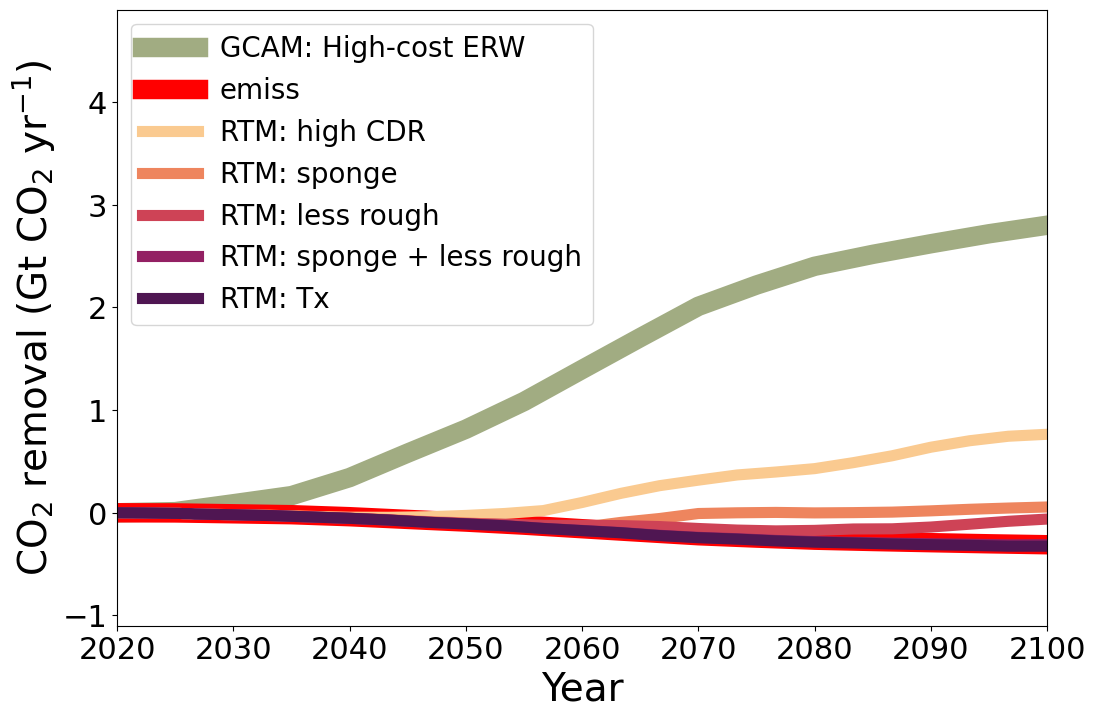

In [389]:
spotlight_cases = ["psdfull_midcec_5xrough"]
emissvar = 'emiss_10percent'
# ---------------------------------
# [ aesthetics ]
# colors
line_cmap_gcam = cmo.cm.rain_r # Choose a cmocean colormap
cmap_gcam_start = 0.1
cmap_gcam_end = 0.7
line_cmap_scep = cmo.cm.matter
cmap_scep_start = 0.1
cmap_scep_end = 0.9
allcases_col = 'black'
allcases_alph = 0.8
# lines
apply_smooth = True  # [] whether to smooth SCEPTER's lines 
ls_case = 14
ls_bg = 8
# legend
legend_on = True
# fontsizes 
fs_ticks = 22
fs_lab = 28
fs_legend = 20
# ---------------------------------
# [ EXP GROUPS TO PLOT ]
EXP_GROUPS_toplot = [
    "psdfull_lowcec", "psdfull_hicec",
    "psdfull_smooth", "psdfull_hicec_smooth",
    "psdfull_loWx",
]
EXP_GROUPS_toplot_MAX = [ # [ ALL cases we want to eventually plot to scale colorbar ]
    "psdfull_lowcec", "psdfull_hicec",
    "psdfull_smooth", "psdfull_hicec_smooth",
    "psdfull_loWx",
]
EXP_GROUP_labels = {
    "psdfull_lowcec": "high CDR", 
    "psdfull_hicec": "sponge",
    "psdfull_smooth": "less rough",
    "psdfull_hicec_smooth": "sponge + less rough",
    "psdfull_loWx": "Tx", 
}
scale_factors = {
    "exe_central1p5": {
        "psdfull_lowcec": 1, "psdfull_hicec": 1, "psdfull_smooth": 1,
        "psdfull_hicec_smooth": 1, "psdfull_loWx": 1,
    },
    "exe_noWeathering1p5": {
        "psdfull_lowcec": 1, "psdfull_hicec": 1, "psdfull_smooth": 1,
        "psdfull_hicec_smooth": 1, "psdfull_loWx": 1,
    }
}
# ---------------------------------

casesonly = True
cases_to_plot = ['exe_central1p5', 'exe_noWeathering1p5']
cases_to_omit = ['exe_ref1p5'] # ref is no policy, and Fuhrman omits it from their figures
casenames = {'exe_central1p5': 'Main', 
             'exe_lowCDR1p5': 'Lower CDR deployment', 
             'exe_noWeathering1p5': 'High-cost ERW', 
             'exe_techBehaviorChange1p5': 'Ambitious behavior change'}
# GCAM --- set colors
n_lines = len(cases_to_plot)
colors = [line_cmap_gcam(i) for i in np.linspace(cmap_gcam_start, cmap_gcam_end, n_lines)]  # spaced colors
order = [0,1]
colors_sorted = [colors[i] for i in order]
# SCEPTER --- set colors
n_lines = len(EXP_GROUPS_toplot_MAX)
colors_scep = [line_cmap_scep(i) for i in np.linspace(cmap_scep_start, cmap_scep_end, n_lines)]  # spaced colors

# [ handle emissions ]
da_emis = (df_global.set_index("time")[emissvar].to_xarray())
da_emis_interp = da_emis.interp(time=ds_trans_dict[EXP_GROUPS_toplot[0]].time+2020, method="nearest")/1e3 # interpolate
# set last value
da_emis_interp[-1] = da_emis_interp[-2].copy()


# pick color for the gcam line 
col_idx = cases_to_plot.index(EXP_SET)

# [ PLOT ] --------------------------------------------------
plt.figure(figsize=(12,8))
# --- gcam line
# plt.plot(df_global['time'], df_global['gcam_gross_cdr_mtCO2']/1e3, c='gray', linewidth=ls_case, label=f'GCAM: {casenames[EXP_SET]}')
plt.plot(df_global['time'], df_global['gcam_gross_cdr_mtCO2']/1e3 - df_global[emissvar]/1e3, c=colors_sorted[col_idx], linewidth=ls_case, label=f'GCAM: {casenames[EXP_SET]}')
plt.plot(df_global['time'], -df_global[emissvar]/1e3, c='red', linewidth=ls_case, label=f'emiss')

# --- scepter lines 
col_scep_idx = 0
for EXP_GROUP in EXP_GROUPS_toplot: # scepter data
    tds_trans = ds_trans_dict[EXP_GROUP]
    xp = tds_trans.time+2020
    yp = tds_trans['cdr_adv_xCropArea_corr'].sum('site')/1e9 * scale_factors[EXP_SET][EXP_GROUP]
    if apply_smooth:
        yp = yp.rolling(time=3, center=True, min_periods=1).mean()
    if EXP_GROUP in spotlight_cases: # give it a thicker line
        plt.plot(xp, yp-da_emis_interp.values, label=f'RTM: {EXP_GROUP_labels[EXP_GROUP]}', linewidth=ls_case, c=colors_scep[col_scep_idx])
    else:
        plt.plot(xp, yp-da_emis_interp.values, label=f'RTM: {EXP_GROUP_labels[EXP_GROUP]}', linewidth=ls_bg, c=colors_scep[col_scep_idx])
    col_scep_idx+=1
if legend_on: 
    handles, labels = plt.gca().get_legend_handles_labels()
    # reorder handles and labels
    # order_leg = len(EXP_GROUPS_toplot)
    # handles = [handles[i] for i in order_leg]
    # labels  = [labels[i] for i in order_leg]
    # draw the legend in the new order
    plt.legend(handles, labels, fontsize=fs_legend)
plt.tick_params(labelsize=fs_ticks)
plt.ylabel(r"CO$_2$ removal (Gt CO$_2$ yr$^{-1}$)", fontsize=fs_lab)
plt.xlabel("Year", fontsize=fs_lab)
plt.xlim(2020, 2100)
plt.ylim(-1.1,4.9)
# plt.yscale('log')
plt.show()
plt.close();#

### Timeseries

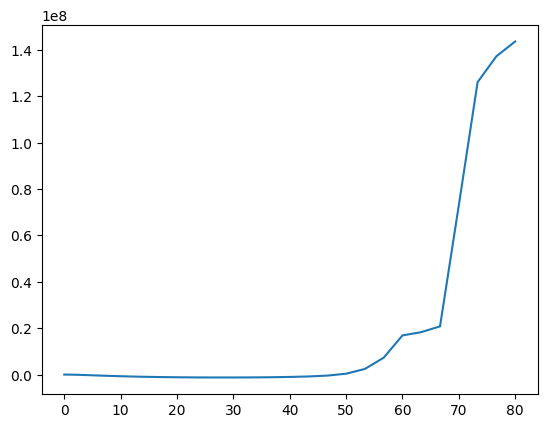

In [397]:
plt.plot(tds_trans.time, tds_trans['cdr_adv_xCropArea_corr'])

/var/folders/2r/w7zcr7vx4p5cr7n4d0b51f4c0000gn/T/ipykernel_60189/1153097947.py:16: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(fontsize=15)


(2020.0, 2100.0)

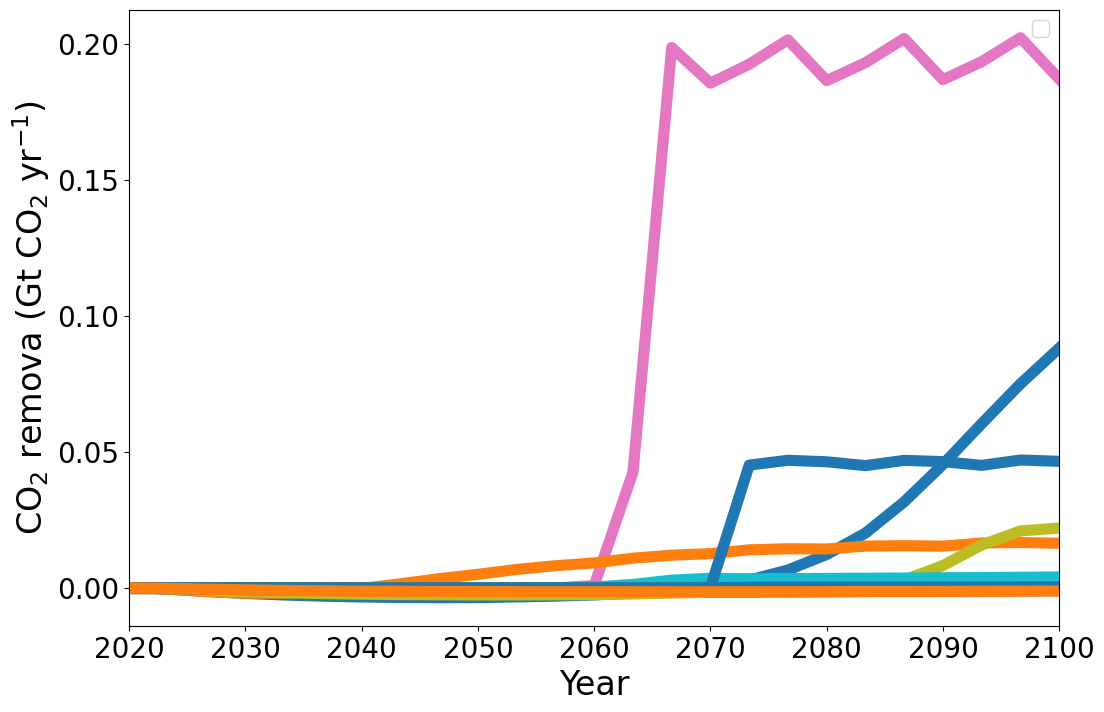

In [408]:
# [ get global sum of CDR ]
fs_ticks = 20
fs_lab = 24
EXP_GROUP_tmp = 'psdfull_hicec'

tdsx = ds_trans_dict[EXP_GROUP_tmp]
allsites = tdsx.site.values

plt.figure(figsize=(12,8))
for sitedx in allsites: # scepter data
    tds_trans = tdsx.sel(site=sitedx)
    plt.plot(tds_trans.time+2020, tds_trans['cdr_adv_xCropArea_corr']/1e9, linewidth=8)
plt.xlabel('year')
# plt.yscale('log')
# plt.ylim(-0.5,1)
plt.legend(fontsize=15)
plt.tick_params(labelsize=fs_ticks)
plt.ylabel(r"CO$_2$ remova (Gt CO$_2$ yr$^{-1}$)", fontsize=fs_lab)
plt.xlabel("Year", fontsize=fs_lab)
plt.xlim(2020, 2100)

(2020.0, 2100.0)

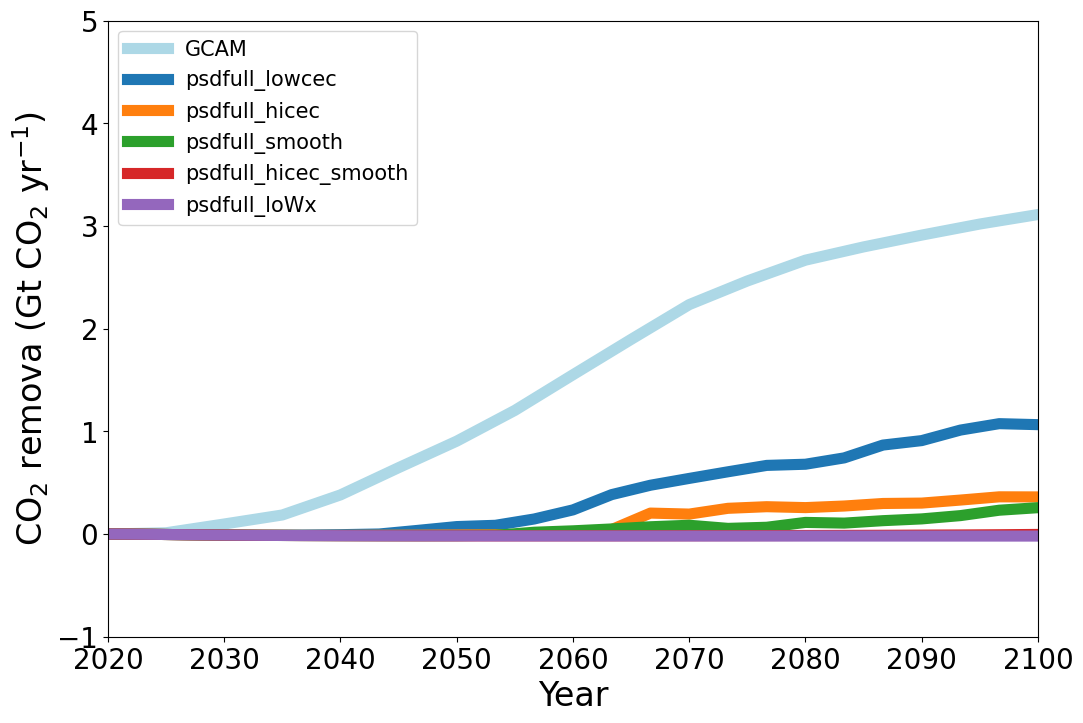

In [391]:
# [ get global sum of CDR ]
fs_ticks = 20
fs_lab = 24

plt.figure(figsize=(12,8))
plt.plot(df_global['time'], df_global['gcam_gross_cdr_mtCO2']/1e3, c='lightblue', linewidth=8, label='GCAM')
for EXP_GROUP in EXP_GROUPS: # scepter data
    tds_trans = ds_trans_dict[EXP_GROUP]
    plt.plot(tds_trans.time+2020, tds_trans['cdr_adv_xCropArea_corr'].sum('site')/1e9, label=EXP_GROUP, linewidth=8)
plt.xlabel('year')
# plt.yscale('log')
plt.ylim(-1,5)
plt.legend(fontsize=15)
plt.tick_params(labelsize=fs_ticks)
plt.ylabel(r"CO$_2$ remova (Gt CO$_2$ yr$^{-1}$)", fontsize=fs_lab)
plt.xlabel("Year", fontsize=fs_lab)
plt.xlim(2020, 2100)

Text(0, 0.5, 'Gt CO2/yr')

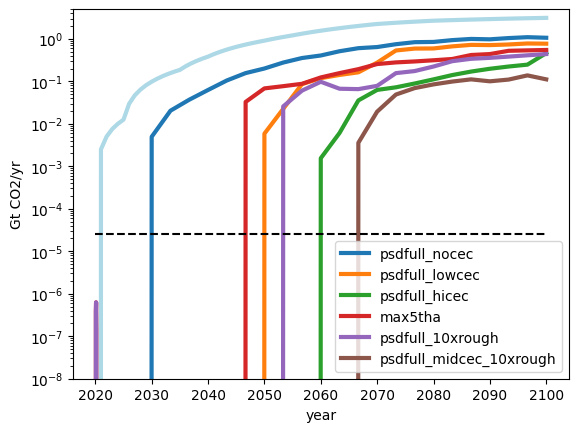

In [69]:

plt.plot(df_global['time'], df_global['gcam_gross_cdr_mtCO2']/1e3, c='lightblue', linewidth=3)
for EXP_GROUP in EXP_GROUPS: # scepter data
    tds_trans = ds_trans_dict[EXP_GROUP]
    plt.plot(tds_trans.time+2020, tds_trans['cdr_adv_xCropArea_corr'].sum('site')/1e9, label=EXP_GROUP, linewidth=3)
# [ add line for pavia and lambert, 2026 ]
# [ 25,000 metric tonnes / yr in US = 2.5e-5 Gt / yr]
plt.hlines(2.5e-5,2020,2100, colors='black', linestyles='dashed')
plt.xlabel('year')
plt.yscale('log')
plt.ylim(1e-8,5) #
plt.legend()
plt.ylabel('Gt CO2/yr')

### SCEPTER fraction GCAM integrated CDR

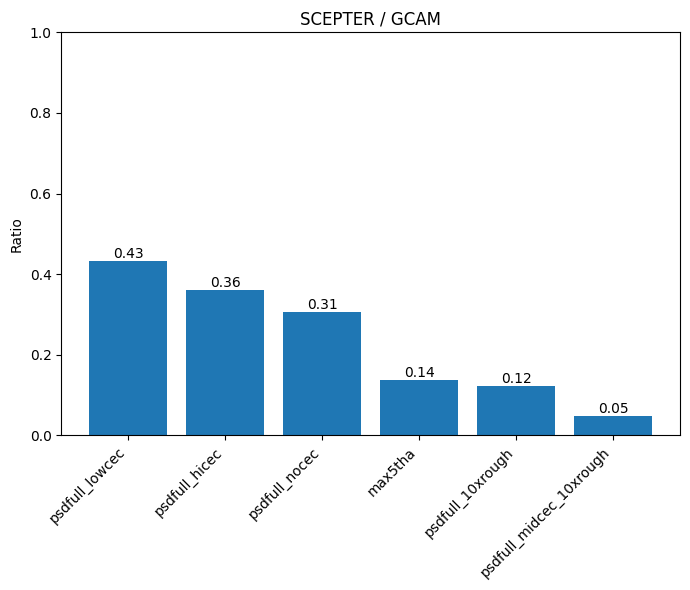

In [125]:
# --- compute time-integrated CDR in Gt
gcam_int = []
scepter_int = []
ratio_int = []
exps = []
for EXP_GROUP in EXP_GROUPS:
    exps.append(EXP_GROUP)
    tds = ds_dict[EXP_GROUP]
    # get integrated cdr timeseries
    gcam_tmp = df_global['gcam_gross_cdr_mtCO2'].cumsum() / 1e3   # [Gt]
    scepter_tmp = ds_dict[EXP_GROUP]['cdr_adv_xCropArea_corr'].sum('site')/1e9  # [Gt]
    # get final values
    gcam_int.append(gcam_tmp.values[-1])
    scepter_int.append(scepter_tmp.values[-1])
    ratio_int.append(scepter_tmp.values[-1] / gcam_tmp.values[-1])

# --- sort by height
idx = np.argsort(ratio_int)[::-1]
exps_sorted = np.array(exps)[idx]
ratio_sorted = np.array(ratio_int)[idx]

# --- PLOT
fig, ax = plt.subplots(figsize=(7, 6))

bars = ax.bar(exps_sorted, ratio_sorted)

ax.set_ylabel("Ratio")
ax.set_title("SCEPTER / GCAM")
ax.set_ylim(0, max(ratio_int) * 1.1)

# optional: add value labels on top
for bar in bars:
    height = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width()/2,
        height,
        f"{height:.2f}",
        ha="center",
        va="bottom"
    )

plt.xticks(rotation=45, ha="right")
plt.ylim(0,1)
# plt.yscale('log')
plt.tight_layout()
plt.show()

In [38]:
gcam_int

[np.float64(284.50875442672316),
 np.float64(284.50875442672316),
 np.float64(284.50875442672316),
 np.float64(284.50875442672316),
 np.float64(284.50875442672316),
 np.float64(284.50875442672316),
 np.float64(284.50875442672316),
 np.float64(284.50875442672316)]